In [1]:

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    adjusted_rand_score,
    silhouette_score
)

HO_TEN = "TRẦN THỊ MỸ DUNG"
MSSV = "6451071008"

def thong_tin(buoc):
    print(f"Họ tên: {HO_TEN}")
    print(f"MSSV: {MSSV}")
    print(f"BÀI 5 TRANG 29 - {buoc}")
    print("-" * 50)

print("Import thư viện thành công!")


Import thư viện thành công!


In [2]:

# Bước 1: Upload và giải nén file dataset ZIP
thong_tin("Upload du lieu")

uploaded = files.upload()
zip_name = next(iter(uploaded))

if not zipfile.is_zipfile(zip_name):
    raise ValueError("Vui lòng chọn đúng file ZIP!")

extract_path = "/content/breast_cancer_dataset"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    for item in zip_ref.infolist():
        destination = os.path.abspath(
            os.path.join(extract_path, item.filename)
        )
        if os.path.commonpath(
            [os.path.abspath(extract_path), destination]
        ) != os.path.abspath(extract_path):
            raise ValueError("ZIP chứa đường dẫn không an toàn!")
    zip_ref.extractall(extract_path)

data_files = []
for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        path = os.path.join(root, filename)
        data_files.append(path)

print("Upload và giải nén thành công!")
print("\nDanh sách file trong ZIP:")
for path in sorted(data_files):
    print(path)


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 TRANG 29 - Upload du lieu
--------------------------------------------------


Saving breast+cancer+wisconsin+diagnostic.zip to breast+cancer+wisconsin+diagnostic.zip
Upload và giải nén thành công!

Danh sách file trong ZIP:
/content/breast_cancer_dataset/wdbc.data
/content/breast_cancer_dataset/wdbc.names


In [3]:

# Bước 2: Đọc dữ liệu ung thư vú từ file đã giải nén
thong_tin("Doc du lieu")

candidates = [
    path for path in data_files
    if os.path.basename(path).lower() in
    ("wdbc.data", "data.csv", "breast_cancer.csv")
]

if not candidates:
    candidates = [
        path for path in data_files
        if path.lower().endswith((".csv", ".data"))
    ]

if not candidates:
    raise ValueError("Không tìm thấy file CSV hoặc DATA trong ZIP!")

data_path = candidates[0]
print("File được chọn:", data_path)

if os.path.basename(data_path).lower() == "wdbc.data":
    df = pd.read_csv(data_path, header=None)
    df.columns = (
        ["id", "diagnosis"] +
        [f"feature_{i}" for i in range(1, 31)]
    )
else:
    df = pd.read_csv(data_path)
    df.columns = df.columns.astype(str).str.strip()

    if "diagnosis" not in df.columns:
        df_no_header = pd.read_csv(data_path, header=None)
        if df_no_header.shape[1] == 32:
            df = df_no_header
            df.columns = (
                ["id", "diagnosis"] +
                [f"feature_{i}" for i in range(1, 31)]
            )

if "diagnosis" not in df.columns:
    raise ValueError(
        f"Chưa xác định được cột diagnosis. "
        f"Các cột: {df.columns.tolist()}"
    )

df["diagnosis"] = (
    df["diagnosis"].astype(str).str.strip().str.upper()
)

if not df["diagnosis"].isin(["M", "B"]).all():
    raise ValueError("Nhãn diagnosis không đúng định dạng M/B!")

print("\nKích thước dữ liệu:", df.shape)
print("\n5 dòng đầu tiên:")
print(df.head().to_string())

print("\nSố lượng theo nhãn:")
print(df["diagnosis"].value_counts())

print("\nSố giá trị thiếu:")
print(df.isnull().sum().sum())


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 TRANG 29 - Doc du lieu
--------------------------------------------------
File được chọn: /content/breast_cancer_dataset/wdbc.data

Kích thước dữ liệu: (569, 32)

5 dòng đầu tiên:
         id diagnosis  feature_1  feature_2  feature_3  feature_4  feature_5  feature_6  feature_7  feature_8  feature_9  feature_10  feature_11  feature_12  feature_13  feature_14  feature_15  feature_16  feature_17  feature_18  feature_19  feature_20  feature_21  feature_22  feature_23  feature_24  feature_25  feature_26  feature_27  feature_28  feature_29  feature_30
0    842302         M      17.99      10.38     122.80     1001.0    0.11840    0.27760     0.3001    0.14710     0.2419     0.07871      1.0950      0.9053       8.589      153.40    0.006399     0.04904     0.05373     0.01587     0.03003    0.006193       25.38       17.33      184.60      2019.0      0.1622      0.6656      0.7119      0.2654      0.4601     0.11890
1    842517         M     

In [4]:

# Bước 3: Xử lý dữ liệu và chuẩn hóa các thuộc tính
thong_tin("Tien xu ly")

y = df["diagnosis"].map({"B": 0, "M": 1}).to_numpy()

X_df = df.drop(
    columns=["id", "ID", "diagnosis"],
    errors="ignore"
)

X_df = X_df.loc[
    :, ~X_df.columns.str.startswith("Unnamed")
]

X_df = X_df.apply(pd.to_numeric, errors="coerce")
X_df = X_df.fillna(X_df.median())

if X_df.isnull().any().any():
    raise ValueError("Dữ liệu vẫn còn giá trị thiếu!")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

print("Kích thước X:", X_scaled.shape)
print("Kích thước y:", y.shape)
print("Số thuộc tính:", X_scaled.shape[1])
print("Dữ liệu đã chuẩn hóa thành công!")


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 TRANG 29 - Tien xu ly
--------------------------------------------------
Kích thước X: (569, 30)
Kích thước y: (569,)
Số thuộc tính: 30
Dữ liệu đã chuẩn hóa thành công!


In [5]:

# Bước 4: Gom dữ liệu ung thư vú thành 2 cụm bằng K-Means
thong_tin("Gom cum K-Means")

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

print("Số cụm:", kmeans.n_clusters)

print("\nSố mẫu trong từng cụm:")
for i in range(2):
    print(f"Cụm {i}: {np.sum(clusters == i)} mẫu")

print("\nInertia:", kmeans.inertia_)


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 TRANG 29 - Gom cum K-Means
--------------------------------------------------
Số cụm: 2

Số mẫu trong từng cụm:
Cụm 0: 375 mẫu
Cụm 1: 194 mẫu

Inertia: 11595.526607115773


In [6]:

# Bước 5: So sánh nhãn gom cụm với nhãn bệnh thực tế
thong_tin("So sanh nhan")

cluster_mapping = {}

for cluster_id in range(2):
    labels_in_cluster = y[clusters == cluster_id]
    cluster_mapping[cluster_id] = np.bincount(
        labels_in_cluster, minlength=2
    ).argmax()

y_pred = np.array([
    cluster_mapping[c] for c in clusters
])

print("Nhãn đại diện của từng cụm:")
for cluster_id, label in cluster_mapping.items():
    name = "Malignant" if label == 1 else "Benign"
    print(f"Cụm {cluster_id}: {name}")

print("\nBảng so sánh cụm và nhãn thực tế:")
print(pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    pd.Series(df["diagnosis"].to_numpy(), name="Diagnosis")
))


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 TRANG 29 - So sanh nhan
--------------------------------------------------
Nhãn đại diện của từng cụm:
Cụm 0: Benign
Cụm 1: Malignant

Bảng so sánh cụm và nhãn thực tế:
Diagnosis    B    M
Cluster            
0          339   36
1           18  176


In [7]:

# Bước 6: Đánh giá kết quả gom cụm bằng các chỉ số
thong_tin("Danh gia ket qua")

accuracy = accuracy_score(y, y_pred)
ari = adjusted_rand_score(y, clusters)
silhouette = silhouette_score(X_scaled, clusters)

print(f"Accuracy: {accuracy:.4f}")
print(f"Adjusted Rand Index: {ari:.4f}")
print(f"Silhouette Score: {silhouette:.4f}")

print("\nClassification Report:")
print(classification_report(
    y,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 TRANG 29 - Danh gia ket qua
--------------------------------------------------
Accuracy: 0.9051
Adjusted Rand Index: 0.6536
Silhouette Score: 0.3434

Classification Report:
              precision    recall  f1-score   support

      Benign       0.90      0.95      0.93       357
   Malignant       0.91      0.83      0.87       212

    accuracy                           0.91       569
   macro avg       0.91      0.89      0.90       569
weighted avg       0.91      0.91      0.90       569



Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 TRANG 29 - Confusion Matrix
--------------------------------------------------


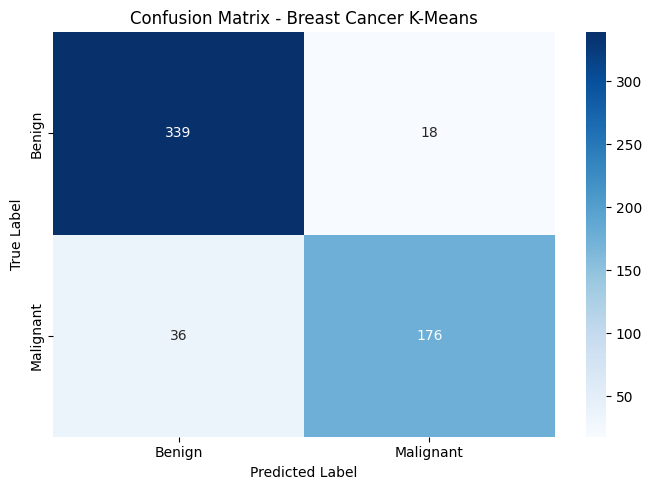

In [8]:

# Bước 7: Vẽ ma trận nhầm lẫn của kết quả gom cụm
thong_tin("Confusion Matrix")

cm = confusion_matrix(y, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Confusion Matrix - Breast Cancer K-Means")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 TRANG 29 - Truc quan hoa
--------------------------------------------------


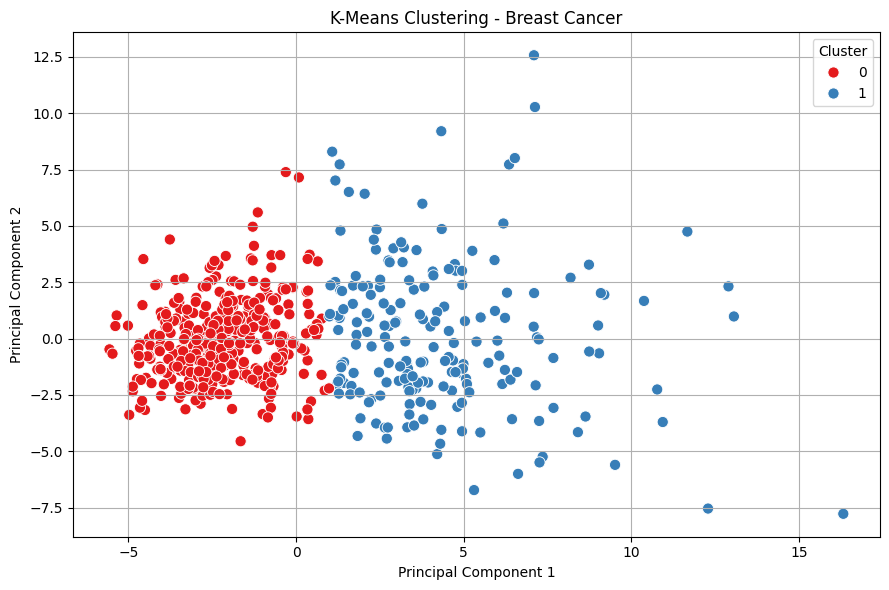

Tỷ lệ phương sai được giải thích:
[0.44272026 0.18971182]


In [9]:

# Bước 8: Trực quan hóa hai cụm bằng PCA
thong_tin("Truc quan hoa")

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters,
    palette="Set1",
    s=65
)

plt.title("K-Means Clustering - Breast Cancer")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Tỷ lệ phương sai được giải thích:")
print(pca.explained_variance_ratio_)
